In [1]:

# IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine-learning models
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# XGBoost
from xgboost import XGBRegressor

# Statistical models
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# File location
file_path = r"C:\Users\suraj\Downloads\1C. Dashboard_data_Henderson.xlsx"

# Load the Main worksheet
df = pd.read_excel(file_path, sheet_name="Main")

In [181]:
# Display first 5 rows
print("First 5 rows:")
display(df.head())

First 5 rows:


,Site,Date,Time,Parameter,Value
0,HEN,2020-11-06,01:00:00,BC(370),-10.87
1,HEN,2018-09-29,11:00:00,BC(370),-10.83
2,HEN,2017-09-17,04:00:00,BC(370),-10.50
3,HEN,2018-05-22,05:00:00,BC(370),-10.50
4,HEN,2020-04-17,23:00:00,BC(880),-10.50


In [4]:
# Check dataset size
print("\nDataset shape:")
print(df.shape)


Dataset shape:
(1048208, 5)


In [5]:
# Check column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Site', 'Date', 'Time', 'Parameter', 'Value']


In [6]:
# Check data types
print("\nData types:")
print(df.dtypes)


Data types:
Site                    str
Date         datetime64[us]
Time                 object
Parameter               str
Value               float64
dtype: object


In [7]:
# Check general information
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1048208 entries, 0 to 1048207
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype         
---  ------     --------------    -----         
 0   Site       1048208 non-null  str           
 1   Date       1048208 non-null  datetime64[us]
 2   Time       1048208 non-null  object        
 3   Parameter  1048208 non-null  str           
 4   Value      1048208 non-null  float64       
dtypes: datetime64[us](1), float64(1), object(1), str(2)
memory usage: 40.0+ MB


In [8]:
#  Check all available parameters
print("Number of unique parameters:")
print(df['Parameter'].nunique())

print("\nAvailable parameters:")
print(sorted(df['Parameter'].unique()))

Number of unique parameters:
11

Available parameters:
['AQI', 'BC(370)', 'BC(880)', 'NO', 'NO2', 'NOx', 'PM10', 'RH', 'Temp', 'WD', 'WS']


In [9]:
# Count observations for each parameter

parameter_counts = df['Parameter'].value_counts()

print("Number of records for each parameter:")
display(parameter_counts)

Number of records for each parameter:


Parameter
PM10       143889
NO2        140510
WS         134623
Temp       133530
RH         133529
NO         132078
NOx        123639
BC(880)     50743
BC(370)     48841
WD           4325
AQI          2501
Name: count, dtype: int64

In [10]:
# Check date range

print("Earliest date:", df['Date'].min())
print("Latest date:", df['Date'].max())

Earliest date: 2006-01-01 00:00:00
Latest date: 2023-02-28 00:00:00


                                                PREPROCESSING

In [185]:
# Selecting parameters
VARS = ["PM10", "NO2", "Temp", "RH", "WS"]
df_sel = df[df["Parameter"].isin(VARS)].copy()
df_sel["Parameter"].value_counts()

Parameter
PM10    143889
NO2     140510
WS      134623
Temp    133530
RH      133529
Name: count, dtype: int64

In [193]:
# Convert the Time column to a time duration (e.g. 05:00:00 -> 5 hours)
time_part = pd.to_timedelta(df_sel["Time"].astype(str))

# 3. Add the date and the time together into a new column called "datetime"
df_sel["datetime"] = df_sel["Date"] + time_part

# 4. Check it worked
df_sel[["Date", "Time", "datetime"]].head()

,Date,Time,datetime
9,2018-02-13,01:00:00,2018-02-13 01:00:00
10,2018-08-05,14:00:00,2018-08-05 14:00:00
15,2017-11-14,16:00:00,2017-11-14 16:00:00
16,2019-09-23,01:00:00,2019-09-23 01:00:00
21,2019-01-15,01:00:00,2019-01-15 01:00:00


In [195]:
# Find duplicate readings
# Mark every row where the same datetime AND parameter appear more than once
# keep=False marks ALL copies of a duplicate (not just the second one), so we can compare them
dup_mask = df_sel.duplicated(subset=["datetime", "Parameter"], keep=False)

# Count how many rows are duplicates (True counts as 1, False as 0)
dup_mask.sum()

np.int64(16864)

In [197]:
# Step 1c, line 3: Which parameters and years are the duplicates in?
# Keep only the duplicate rows, then count them by parameter and year
dups = df_sel[dup_mask]
dups.groupby(["Parameter", dups["datetime"].dt.year]).size()

Parameter  datetime
NO2        2011        16864
dtype: int64

In [199]:
# Step 1c, line 4: Compare the two values in each duplicate pair
# For each datetime + parameter, show the smaller and larger of the two values
pairs = dups.groupby(["datetime", "Parameter"])["Value"].agg(["min", "max"])
pairs.head(10)

,,min,max
datetime,Parameter,,
2011-01-01 00:00:00,NO2,3.41484,8.978285
2011-01-01 01:00:00,NO2,4.25751,15.442699
2011-01-01 02:00:00,NO2,2.49588,8.053333
2011-01-01 03:00:00,NO2,1.04140,3.005621
2011-01-01 04:00:00,NO2,0.86533,2.887037
2011-01-01 05:00:00,NO2,0.61272,1.620000
2011-01-01 06:00:00,NO2,0.91589,2.818926
2011-01-01 07:00:00,NO2,1.19447,3.904110
2011-01-01 08:00:00,NO2,1.44343,7.579633


In [201]:
# Step 1c, line 4b: Compare the average of the min and max columns
# with normal NO2 levels in the years either side of 2011
print("Average of min values:", pairs["min"].mean())
print("Average of max values:", pairs["max"].mean())
print("NO2 average 2010:", df_sel[(df_sel["Parameter"] == "NO2") & (df_sel["datetime"].dt.year == 2010)]["Value"].mean())
print("NO2 average 2012:", df_sel[(df_sel["Parameter"] == "NO2") & (df_sel["datetime"].dt.year == 2012)]["Value"].mean())

Average of min values: 12.313932276644527
Average of max values: 86.20685580142262
NO2 average 2010: 12.712181278727165
NO2 average 2012: 12.814070724362775


In [203]:
# Step 1c, line 6: Keep only the real NO2 value for each duplicate pair
# Sort by Value (smallest first), so the smaller (real NO2) value comes first in each pair,
# then drop duplicates keeping the first one = the minimum
df_sel = df_sel.sort_values("Value").drop_duplicates(subset=["datetime", "Parameter"], keep="first")

# Put the rows back in time order
df_sel = df_sel.sort_values(["datetime", "Parameter"])

In [205]:
# Step 1c, line 7: Check the fix worked
# Should be 0 duplicates left
print("Duplicates remaining:", df_sel.duplicated(subset=["datetime", "Parameter"]).sum())

# 2011 NO2 average should now be around 12-13, not 49
print("NO2 average 2011:", df_sel[(df_sel["Parameter"] == "NO2") & (df_sel["datetime"].dt.year == 2011)]["Value"].mean())

# Total rows should be 686,081 - 8,432 = 677,649
print("Rows:", len(df_sel))

Duplicates remaining: 0
NO2 average 2011: 12.311054473164177
Rows: 677649


In [207]:
# Step 1d, line 1: Reshape from long to wide
# Right now there is one row per reading (e.g. 5 rows for one hour: PM10, NO2, Temp, RH, WS).
# pivot_table turns each Parameter into its own column, so each hour becomes ONE row.
wide = df_sel.pivot_table(index="datetime", columns="Parameter", values="Value")

# Look at the result
wide.head()

Parameter,NO2,PM10,RH,Temp,WS
datetime,,,,,
2006-01-01 00:00:00,1.50,18.4,80.3,19.0,1.3
2006-01-01 01:00:00,0.76,32.6,81.1,19.0,3.1
2006-01-01 02:00:00,0.46,18.6,80.4,20.0,2.7
2006-01-01 03:00:00,0.42,15.1,79.4,20.0,1.6
2006-01-01 04:00:00,0.40,15.6,80.4,20.0,1.4


In [225]:
# Step 1d, line 2: Make sure every hour exists in the table
# If an hour had no readings at all, it is simply missing from 'wide'.
# Build a complete list of every hour from the first to the last timestamp...
all_hours = pd.date_range(start=wide.index.min(), end=wide.index.max(), freq="h")

# ...and reindex, so missing hours appear as empty rows (NaN) instead of being skipped
wide = wide.reindex(all_hours)
wide.index.name = "datetime"

# Check: number of rows and columns
print("Shape:", wide.shape)
print("Missing hours per variable:")
print(wide.isna().sum())

Shape: (150432, 5)
Missing hours per variable:
Parameter
NO2     18354
PM10     6543
RH      17777
Temp    16902
WS      15809
dtype: int64


In [235]:
# RH of exactly 0 is a sensor fault -> treat as missing
wide.loc[wide["RH"] == 0, "RH"] = np.nan

# check: should be 0
(wide["RH"] == 0).sum()

np.int64(0)

In [237]:
# count negative values in each column
(wide < 0).sum()

Parameter
NO2     0
PM10    0
RH      0
Temp    2
WS      0
dtype: int64

In [239]:
# negative PM10 and NO2 -> 0
wide[["PM10", "NO2"]] = wide[["PM10", "NO2"]].clip(lower=0)

# check: should be 0 for both
(wide[["PM10", "NO2"]] < 0).sum()

Parameter
PM10    0
NO2     0
dtype: int64

In [241]:
# mark which values are missing
na = wide.isna()

# length of each run of missing hours
gap_len = na.apply(lambda s: s.groupby((~s).cumsum()).transform("sum"))

# interpolate, then blank out anything inside a gap longer than 6 hours
wide_filled = wide.interpolate(method="time", limit_area="inside").mask(na & (gap_len > 6))

print("Before:", wide.isna().sum().sum())
print("After:", wide_filled.isna().sum().sum())
print(wide_filled.isna().sum())

Before: 75385
After: 68680
Parameter
NO2     14580
PM10     4153
RH      17549
Temp    16747
WS      15651
dtype: int64


In [243]:
# hours around the biggest PM10 value
wide_filled.loc["2007-06-27 08:00":"2007-06-27 15:00", "PM10"]

# suspiciously low humidity
(wide_filled["RH"] < 10).sum()

np.int64(0)

In [247]:
# save clean data
wide_filled.to_csv("henderson_clean_final_data.csv")

                                                 EDA

# IMPROVEMENT EXPERIMENTS (PM10 focus)

Steps added after the original model comparison:

1. **Diagnostic** – how predictable is hourly PM10 each year? (lag-1 autocorrelation, noise, negative readings)
2. **Fair evaluation** – score models only on hours where the target was actually measured, not filled by ffill/median
3. **Extra features** – short rolling windows, volatility, changes, cyclical time, imputation flag
4. **XGBoost variants** – original vs extra features vs log target vs Huber loss, with early stopping
5. **Scenario** – forecasting the next 24-hour mean PM10 (the basis of the NZ PM10 standard)

,PM10_observed_hours,PM10_lag1_autocorr,NO2_lag1_autocorr,PM10_std,PM10_mean_abs_hourly_change,PM10_negative_raw_%
Timestamp,,,,,,
2006,8589,0.684,0.853,11.723,6.235,0.000
2007,8379,0.661,0.828,14.760,6.226,0.000
2008,8525,0.594,0.811,8.698,5.657,0.000
2009,8698,0.786,0.827,12.866,4.682,0.000
2010,8711,0.658,0.830,7.784,4.585,0.000
2011,8665,0.649,0.809,7.248,4.412,1.258
2012,8733,0.658,0.834,8.251,4.769,0.973
2013,8701,0.636,0.825,7.988,4.825,0.873
2014,8526,0.603,0.817,8.224,5.074,1.501


Train period PM10 lag-1 autocorrelation: 0.663
Test period PM10 lag-1 autocorrelation:  0.423


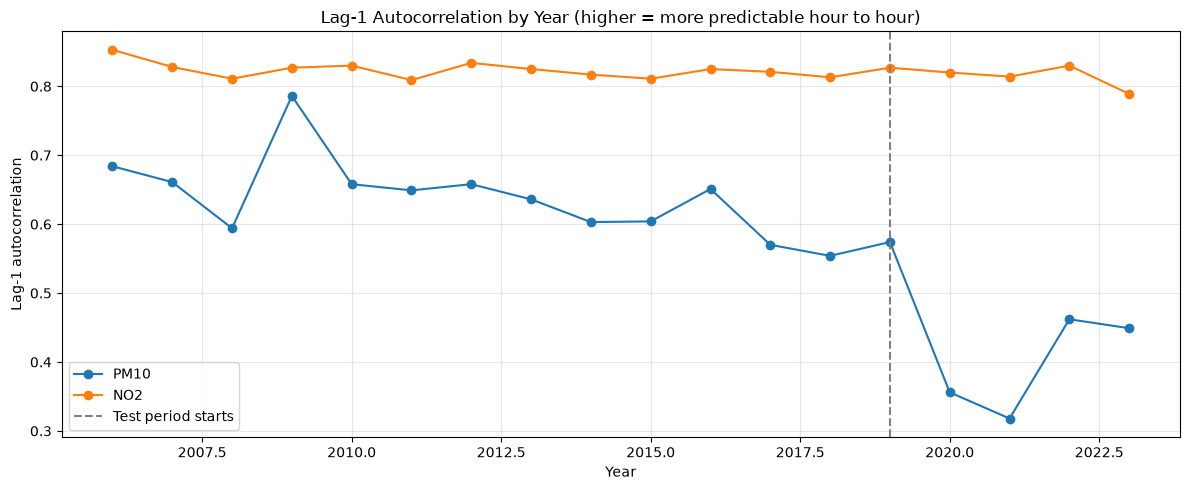

In [87]:
# STEP 1 - PM10 PREDICTABILITY DIAGNOSTIC

# Uses df_wide (BEFORE imputation) and df_raw (BEFORE clipping negatives).
# Low lag-1 autocorrelation = hour-to-hour changes are mostly noise,
# which caps what ANY one-hour-ahead model can achieve.

obs_lookup = df_wide.set_index('Timestamp')

pm10_obs = obs_lookup['PM10']
no2_obs = obs_lookup['NO2']
pm10_raw_long = df_raw[df_raw['Parameter'] == 'PM10']

def lag1_autocorr(s):
    return s.autocorr(lag=1)

pm10_diagnostic = pd.DataFrame({
    'PM10_observed_hours': pm10_obs.groupby(pm10_obs.index.year).count(),
    'PM10_lag1_autocorr': pm10_obs.groupby(pm10_obs.index.year).apply(lag1_autocorr),
    'NO2_lag1_autocorr': no2_obs.groupby(no2_obs.index.year).apply(lag1_autocorr),
    'PM10_std': pm10_obs.groupby(pm10_obs.index.year).std(),
    'PM10_mean_abs_hourly_change': pm10_obs.diff().abs().groupby(pm10_obs.index.year).mean(),
    'PM10_negative_raw_%': (
        pm10_raw_long
        .groupby(pm10_raw_long['Timestamp'].dt.year)['Value']
        .apply(lambda v: (v < 0).mean() * 100)
    ),
}).round(3)

display(pm10_diagnostic)

print("Train period PM10 lag-1 autocorrelation:",
      round(pm10_obs[pm10_obs.index < test_start].autocorr(lag=1), 3))
print("Test period PM10 lag-1 autocorrelation: ",
      round(pm10_obs[pm10_obs.index >= test_start].autocorr(lag=1), 3))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pm10_diagnostic.index, pm10_diagnostic['PM10_lag1_autocorr'], marker='o', label='PM10')
ax.plot(pm10_diagnostic.index, pm10_diagnostic['NO2_lag1_autocorr'], marker='o', label='NO2')
ax.axvline(test_start.year, color='grey', linestyle='--', label='Test period starts')
ax.set_title('Lag-1 Autocorrelation by Year (higher = more predictable hour to hour)')
ax.set_xlabel('Year')
ax.set_ylabel('Lag-1 autocorrelation')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [88]:
# STEP 2 - FAIR EVALUATION ON OBSERVED TARGETS ONLY

# Missing hours were filled (ffill up to 6 h, then training median).
# Scoring against filled values is misleading, so existing models are
# re-scored on hours where the target was actually measured.

for p in pollutants:
    df_model_ready[f'{p}_target_observed'] = (
        df_model_ready['TargetTimestamp'].map(obs_lookup[p]).notna().values
    )

observed_rows = []

for p in pollutants:

    y_all = df_model_ready.loc[test_mask, f'{p}_target_1h'].values
    observed = df_model_ready.loc[test_mask, f'{p}_target_observed'].values

    print(f"{p}: {observed.mean() * 100:.1f}% of test targets were actually measured")

    for (pol, model_name), pred in prediction_store.items():

        if pol != p or model_name == 'SARIMA':
            continue

        pred = np.asarray(pred)

        observed_rows.append({
            'Pollutant': p,
            'Model': model_name,
            'RMSE_all_hours': np.sqrt(mean_squared_error(y_all, pred)),
            'RMSE_observed': np.sqrt(mean_squared_error(y_all[observed], pred[observed])),
            'MAE_observed': mean_absolute_error(y_all[observed], pred[observed]),
            'R2_observed': r2_score(y_all[observed], pred[observed])
        })

observed_results = (
    pd.DataFrame(observed_rows)
    .sort_values(['Pollutant', 'RMSE_observed'])
    .round(3)
    .reset_index(drop=True)
)

display(observed_results)

PM10: 90.4% of test targets were actually measured
NO2: 92.2% of test targets were actually measured


,Pollutant,Model,RMSE_all_hours,RMSE_observed,MAE_observed,R2_observed
0,NO2,XGBoost,3.962,4.039,2.494,0.752
1,NO2,Random Forest,4.071,4.157,2.558,0.737
2,NO2,Decision Tree,4.324,4.418,2.727,0.703
3,NO2,SVR,4.433,4.611,2.706,0.676
4,NO2,AR Lag Regression,4.467,4.644,3.008,0.671
5,NO2,Persistence,4.713,4.905,2.808,0.634
6,PM10,XGBoost,6.417,6.687,4.523,0.257
7,PM10,SVR,6.592,6.891,4.695,0.211
8,PM10,AR Lag Regression,6.699,7.013,4.839,0.183
9,PM10,Random Forest,6.798,7.092,4.589,0.164


In [89]:
# STEP 3 - EXTRA FEATURES

# The target is the value at t+1, so any window that ENDS at t
# (the current hour) uses only past information: no leakage.

exp = df_models.copy()

for p in pollutants:

    s = exp[p]

    exp[f'{p}_lag2'] = s.shift(2)
    exp[f'{p}_diff1'] = s - s.shift(1)

    for w in [3, 6, 24]:
        exp[f'{p}_rmean{w}'] = s.rolling(w).mean()
        exp[f'{p}_rstd{w}'] = s.rolling(w).std()
        exp[f'{p}_rmax{w}'] = s.rolling(w).max()

    # 1 if the current value was filled rather than measured
    exp[f'{p}_imputed'] = exp['Timestamp'].map(obs_lookup[p]).isna().astype(int).values

    # True if the value being predicted was actually measured
    exp[f'{p}_target_observed'] = exp['TargetTimestamp'].map(obs_lookup[p]).notna().values

# Weather changes
for col in ['WS', 'RH', 'Temp']:
    exp[f'{col}_diff1'] = exp[col] - exp[col].shift(1)

exp['WS_rmean3'] = exp['WS'].rolling(3).mean()

# Cyclical time (hour 23 is next to hour 0)
exp['hour_sin'] = np.sin(2 * np.pi * exp['Hour'] / 24)
exp['hour_cos'] = np.cos(2 * np.pi * exp['Hour'] / 24)
exp['month_sin'] = np.sin(2 * np.pi * (exp['Month'] - 1) / 12)
exp['month_cos'] = np.cos(2 * np.pi * (exp['Month'] - 1) / 12)
exp['is_weekend'] = (exp['DayOfWeek'] >= 5).astype(int)


def get_features_v2(target_pollutant):

    other = 'NO2' if target_pollutant == 'PM10' else 'PM10'

    extra = [
        f'{target_pollutant}_lag2',
        f'{target_pollutant}_diff1',
        *[f'{target_pollutant}_{stat}{w}'
          for stat in ['rmean', 'rstd', 'rmax']
          for w in [3, 6, 24]],
        f'{target_pollutant}_imputed',
        f'{other}_lag1',
        f'{other}_diff1',
        'WS_diff1', 'RH_diff1', 'Temp_diff1', 'WS_rmean3',
        'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_weekend'
    ]

    return get_features(target_pollutant) + extra


all_needed = set()
for p in pollutants:
    all_needed.update(get_features_v2(p))
    all_needed.add(f'{p}_target_1h')

exp_ready = (
    exp
    .dropna(subset=sorted(all_needed))
    .reset_index(drop=True)
)

exp_train = exp_ready['TargetTimestamp'] < test_start
exp_test = exp_ready['TargetTimestamp'] >= test_start

print("Extra features created.")
print("PM10 feature count:", len(get_features('PM10')), "->", len(get_features_v2('PM10')))
print("Training rows:", exp_train.sum(), "| Testing rows:", exp_test.sum())

Extra features created.
PM10 feature count: 13 -> 36
Training rows: 120176 | Testing rows: 30087


In [90]:
# STEP 4 - XGBOOST VARIANTS

# - Trained only on hours where the target was really measured
# - Last 10% of the training period (chronological) used for early stopping
# - Evaluated on measured test hours, compared against persistence


def fit_xgb(X_tr, y_tr, X_te, objective='reg:squarederror', log_target=False, **extra_params):

    cut = int(len(X_tr) * 0.9)

    y_fit = np.log1p(y_tr) if log_target else y_tr

    model = XGBRegressor(
        n_estimators=2000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=10,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method='hist',
        objective=objective,
        early_stopping_rounds=100,
        random_state=42,
        n_jobs=-1,
        **extra_params
    )

    model.fit(
        X_tr.iloc[:cut], y_fit.iloc[:cut],
        eval_set=[(X_tr.iloc[cut:], y_fit.iloc[cut:])],
        verbose=False
    )

    pred = model.predict(X_te)

    if log_target:
        pred = np.expm1(pred)

    return model, np.clip(pred, 0, None)


def score(y_true, y_pred, baseline_rmse=None):

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    out = {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': rmse,
        'R2': r2_score(y_true, y_pred)
    }

    if baseline_rmse is not None:
        # % RMSE reduction compared with persistence
        out['Skill_vs_persistence_%'] = (1 - rmse / baseline_rmse) * 100

    return out


improvement_rows = []
improved_models = {}
improved_predictions = {}

for p in pollutants:

    target = f'{p}_target_1h'

    train_rows = exp_train & exp_ready[f'{p}_target_observed']
    test_rows = exp_test & exp_ready[f'{p}_target_observed']

    y_tr = exp_ready.loc[train_rows, target]
    y_te = exp_ready.loc[test_rows, target]

    # Persistence on the same measured test hours
    persistence = exp_ready.loc[test_rows, p]
    base_rmse = np.sqrt(mean_squared_error(y_te, persistence))

    improvement_rows.append({
        'Pollutant': p, 'Model': 'Persistence',
        **score(y_te, persistence, base_rmse)
    })

    variants = {
        'XGB original features': dict(features=get_features(p)),
        'XGB + extra features': dict(features=get_features_v2(p)),
        'XGB + extra + log target': dict(features=get_features_v2(p), log_target=True),
        'XGB + extra + Huber loss': dict(features=get_features_v2(p),
                                         objective='reg:pseudohubererror',
                                         huber_slope=5.0),
    }

    for name, cfg in variants.items():

        cfg = dict(cfg)
        feats = cfg.pop('features')

        model, pred = fit_xgb(
            exp_ready.loc[train_rows, feats], y_tr,
            exp_ready.loc[test_rows, feats],
            **cfg
        )

        improved_models[(p, name)] = (model, feats)
        improved_predictions[(p, name)] = pred

        improvement_rows.append({
            'Pollutant': p, 'Model': name,
            **score(y_te, pred, base_rmse)
        })

        print(f"{p} | {name} done (trees used: {model.best_iteration + 1})")

improvement_results = (
    pd.DataFrame(improvement_rows)
    .sort_values(['Pollutant', 'RMSE'])
    .round(3)
    .reset_index(drop=True)
)

print("\nOne-hour-ahead results on MEASURED test hours:")
display(improvement_results)

PM10 | XGB original features done (trees used: 324)
PM10 | XGB + extra features done (trees used: 1168)
PM10 | XGB + extra + log target done (trees used: 1677)
PM10 | XGB + extra + Huber loss done (trees used: 1611)
NO2 | XGB original features done (trees used: 841)
NO2 | XGB + extra features done (trees used: 803)
NO2 | XGB + extra + log target done (trees used: 1019)
NO2 | XGB + extra + Huber loss done (trees used: 1261)

One-hour-ahead results on MEASURED test hours:


,Pollutant,Model,MAE,RMSE,R2,Skill_vs_persistence_%
0,NO2,XGB + extra + Huber loss,2.382,3.922,0.766,20.038
1,NO2,XGB + extra + log target,2.314,3.934,0.764,19.787
2,NO2,XGB + extra features,2.449,3.958,0.761,19.304
3,NO2,XGB original features,2.492,4.017,0.754,18.096
4,NO2,Persistence,2.808,4.905,0.634,0.000
5,PM10,XGB + extra + Huber loss,4.448,6.585,0.280,21.448
6,PM10,XGB + extra + log target,4.409,6.612,0.274,21.125
7,PM10,XGB original features,4.521,6.619,0.272,21.034
8,PM10,XGB + extra features,4.468,6.676,0.260,20.361
9,PM10,Persistence,5.783,8.382,-0.167,0.000


Best PM10 variant: XGB + extra + Huber loss


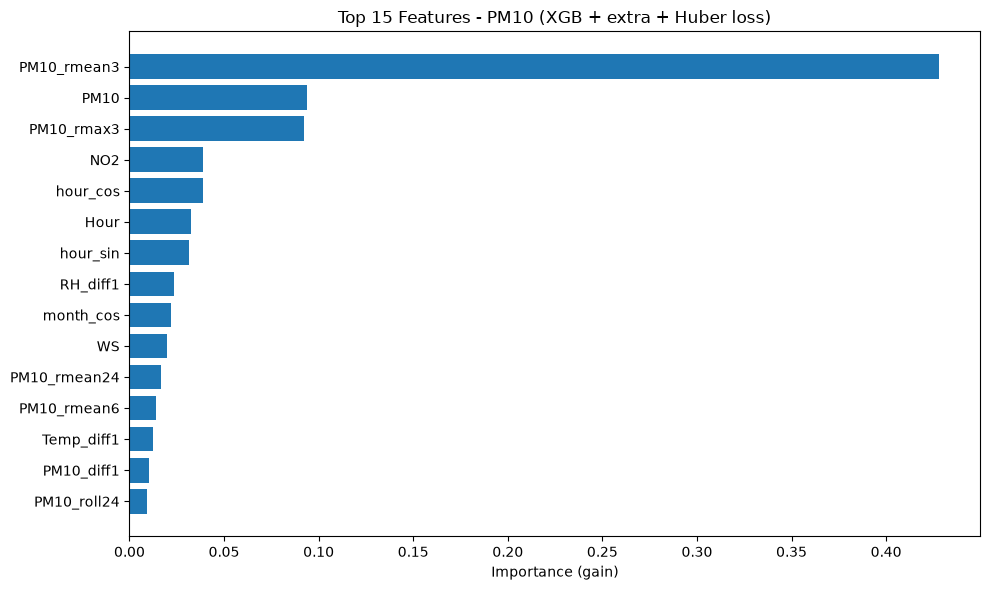

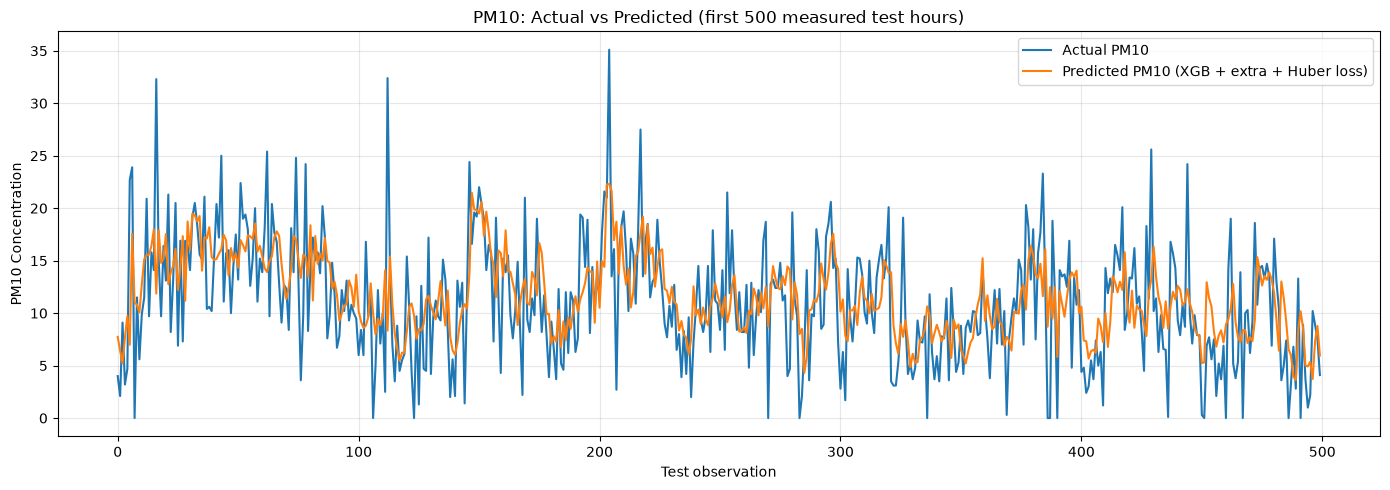

In [91]:
# STEP 4b - BEST VARIANT: FEATURE IMPORTANCE AND ACTUAL VS PREDICTED (PM10)

pm10_variants = improvement_results[
    (improvement_results['Pollutant'] == 'PM10') &
    (improvement_results['Model'] != 'Persistence')
]

best_pm10_name = pm10_variants.iloc[0]['Model']
best_pm10_model, best_pm10_feats = improved_models[('PM10', best_pm10_name)]

print("Best PM10 variant:", best_pm10_name)

importance = (
    pd.Series(best_pm10_model.feature_importances_, index=best_pm10_feats)
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
plt.barh(importance.index[::-1], importance.values[::-1])
plt.title(f'Top 15 Features - PM10 ({best_pm10_name})')
plt.xlabel('Importance (gain)')
plt.tight_layout()
plt.show()

test_rows = exp_test & exp_ready['PM10_target_observed']
pm10_actual_obs = exp_ready.loc[test_rows, 'PM10_target_1h'].values
pm10_pred_obs = improved_predictions[('PM10', best_pm10_name)]

plt.figure(figsize=(14, 5))
plt.plot(pm10_actual_obs[:500], label='Actual PM10')
plt.plot(pm10_pred_obs[:500], label=f'Predicted PM10 ({best_pm10_name})')
plt.title('PM10: Actual vs Predicted (first 500 measured test hours)')
plt.xlabel('Test observation')
plt.ylabel('PM10 Concentration')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Scenario: next 24-hour mean PM10

The NZ PM10 standard is based on a **24-hour average**, so forecasting the mean of the next 24 hours is directly relevant for health reporting.
This is a **different, smoother problem** than one-hour-ahead, so it is reported separately and not compared directly with the hourly results.

Next-24-hour mean PM10 forecast (test period):


,Model,MAE,RMSE,R2,Skill_vs_persistence_%
0,Persistence (last 24 h mean),2.743,3.776,0.077,0.000
1,XGBoost + extra features,2.665,3.504,0.205,7.198


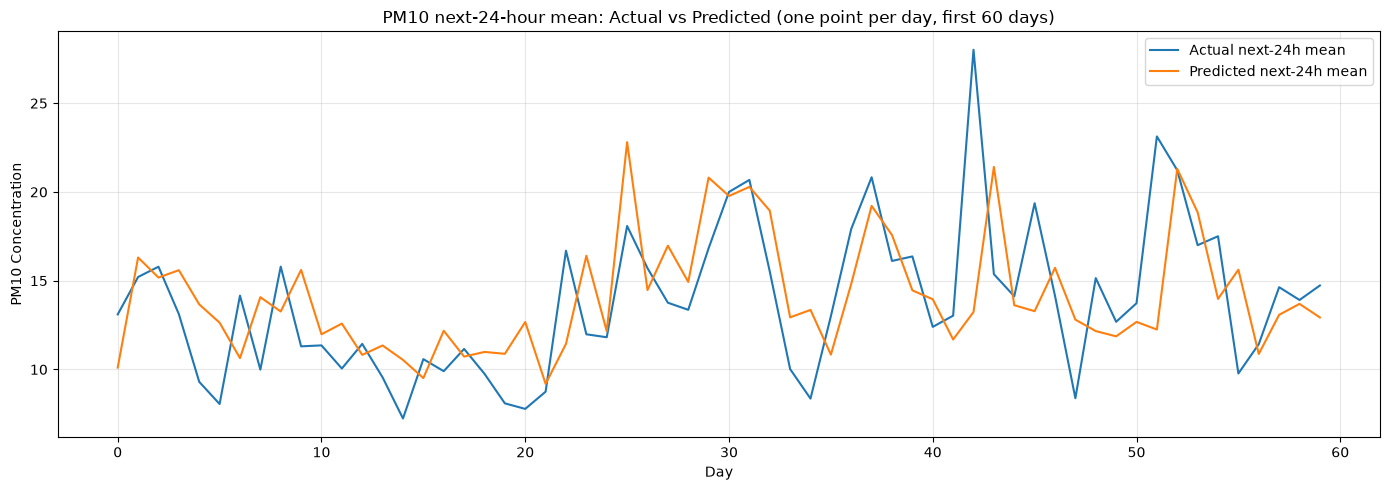

In [93]:
# STEP 5 - FORECAST THE NEXT 24-HOUR MEAN PM10

H = 24

# Mean of hours t+1 ... t+24
exp['PM10_target_24hmean'] = exp['PM10'].rolling(H).mean().shift(-H)

# Share of those 24 hours that were really measured
pm10_measured = exp['Timestamp'].map(obs_lookup['PM10']).notna().astype(float).values
exp['PM10_24h_measured_frac'] = (
    pd.Series(pm10_measured, index=exp.index).rolling(H).mean().shift(-H)
)

feats_24h = get_features_v2('PM10')

d24 = (
    exp
    .dropna(subset=feats_24h + ['PM10_target_24hmean', 'PM10_24h_measured_frac'])
    .reset_index(drop=True)
)

# Keep windows with at least 75% measured hours
valid = d24['PM10_24h_measured_frac'] >= 0.75

# Whole 24-hour target window must sit inside train or inside test
train_24 = valid & (d24['Timestamp'] + pd.Timedelta(hours=H) < test_start)
test_24 = valid & (d24['Timestamp'] >= test_start)

y_tr_24 = d24.loc[train_24, 'PM10_target_24hmean']
y_te_24 = d24.loc[test_24, 'PM10_target_24hmean']

# Baseline: mean of the last 24 hours
baseline_24 = d24.loc[test_24, 'PM10_rmean24']
base_rmse_24 = np.sqrt(mean_squared_error(y_te_24, baseline_24))

model_24, pred_24 = fit_xgb(
    d24.loc[train_24, feats_24h], y_tr_24,
    d24.loc[test_24, feats_24h]
)

results_24h = pd.DataFrame([
    {'Model': 'Persistence (last 24 h mean)', **score(y_te_24, baseline_24, base_rmse_24)},
    {'Model': 'XGBoost + extra features', **score(y_te_24, pred_24, base_rmse_24)},
]).round(3)

print("Next-24-hour mean PM10 forecast (test period):")
display(results_24h)

plt.figure(figsize=(14, 5))
plt.plot(y_te_24.values[:24 * 60:24], label='Actual next-24h mean')
plt.plot(pred_24[:24 * 60:24], label='Predicted next-24h mean')
plt.title('PM10 next-24-hour mean: Actual vs Predicted (one point per day, first 60 days)')
plt.xlabel('Day')
plt.ylabel('PM10 Concentration')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
# STEP 6 - SAVE IMPROVEMENT RESULTS

observed_results.to_csv('Henderson_observed_only_evaluation.csv', index=False)
improvement_results.to_csv('Henderson_improvement_experiments.csv', index=False)
results_24h.to_csv('Henderson_PM10_24h_mean_forecast.csv', index=False)

print("Improvement results saved.")

Improvement results saved.


In [95]:

# 62. SAVE RESULTS


results_df.to_csv(
    'Henderson_PM10_NO2_model_comparison.csv',
    index=False
)

best_models.to_csv(
    'Henderson_PM10_NO2_best_models.csv',
    index=False
)

print(
    "PM10 and NO2 model results saved successfully."
)

PM10 and NO2 model results saved successfully.


In [96]:

# SAVE CLEANED DATASET


df_clean.to_csv(
    'Henderson_PM10_NO2_cleaned_long_data.csv',
    index=False
)

df_wide.to_csv(
    'Henderson_PM10_NO2_hourly_data.csv',
    index=False
)

print(
    "Cleaned PM10 and NO2 datasets saved successfully."
)

Cleaned PM10 and NO2 datasets saved successfully.
